# Assignment 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
def minmax_normalize(img):
    """Normalize image to [0, 1] range.
    
    Args:
        img: Input image (any range).
        
    Returns:
        Normalized image (float32 in range [0,1]).
    """
    return cv2.normalize(img, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)

## Question 1

**Noise Reduction:**
 
**A)** Read the image 'bridge.gif'. Filter the images using the masks of of 3x3, 5x5 and 7x7. How does the size of the mask affect blurring and noise reduction? Which do you think provides a better tradeoff between blurring and noise reduction for this image?

**B)** Sharpen the 3x3 blurred image by convolving with the Laplacian mask

0 -1 0  
-1 5 -1     
0 -1 0  
Display and submit. Does this operation reduce the blurring? What about the original noise? You might need to rescale this image after convolving to make the effect more visible and to make the contrast more pleasing.

**C)** Apply a second sharpening step as in (B). Display and submit. Would repeated sharpening help image interpretation? Again, rescaling will be needed to see the effect.

<img src="./imgs/bridge.gif" width="200" height="200"/>

(-0.5, 511.5, 511.5, -0.5)

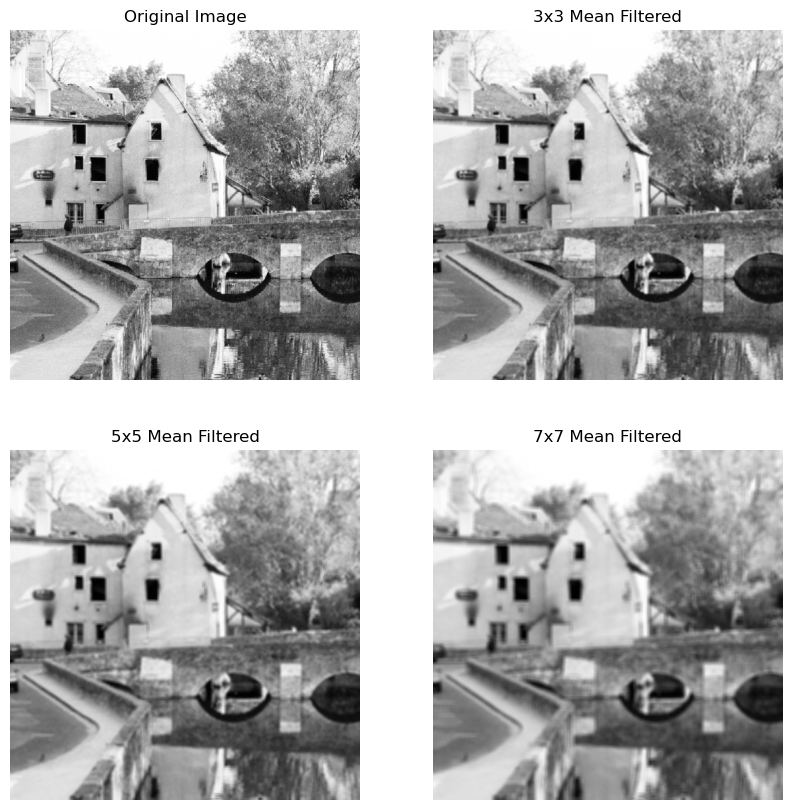

In [3]:
# Answer for A : Applying mean filter with different masks.

# Reading image in gif format.
cap = cv2.VideoCapture("./imgs/bridge.gif")
_, ex1_image = cap.read()
cap.release()
ex1_image = cv2.cvtColor(ex1_image, cv2.COLOR_BGR2GRAY)
ex1_image = minmax_normalize(ex1_image)

mask_3x3 = np.ones((3,3)) / 9
mask_5x5 = np.ones((5, 5)) / 25
mask_7x7 = np.ones((7, 7)) / 49

output_3x3 = cv2.filter2D(ex1_image, -1, mask_3x3)
output_5x5 = cv2.filter2D(ex1_image, -1, mask_5x5)
output_7x7 = cv2.filter2D(ex1_image, -1, mask_7x7)

plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(ex1_image, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title('3x3 Mean Filtered')
plt.imshow(output_3x3, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title('5x5 Mean Filtered')
plt.imshow(output_5x5, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('7x7 Mean Filtered')
plt.imshow(output_7x7, cmap='gray')
plt.axis('off')
#plt.savefig('./results/q1a.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

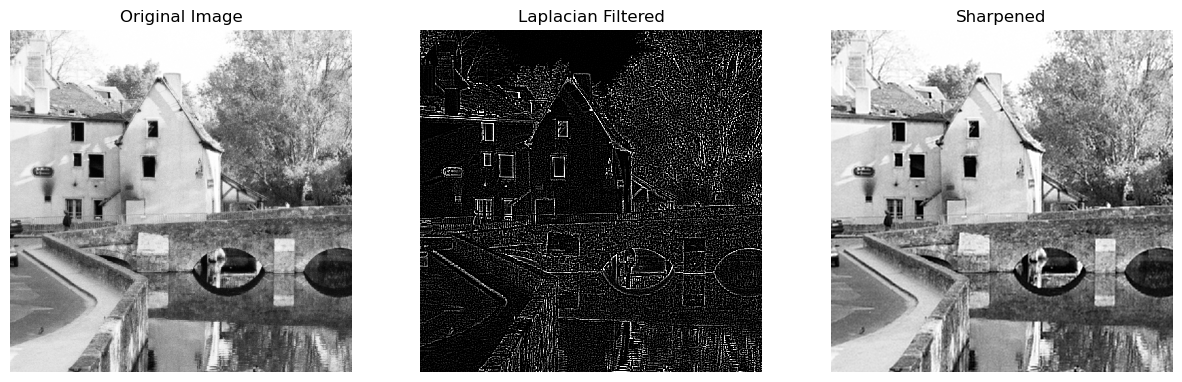

In [4]:
# Answer for B : Applying sharpening filter to the 3x3 blurred image.
laplacian_mask = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
ex1_image_lf = cv2.Laplacian(ex1_image, -1, ksize=3)
ex1_image_sharp = cv2.filter2D(output_3x3, -1, laplacian_mask)

plt.figure(figsize=(15,6))

plt.subplot(1,3,1)
plt.title('Original Image')
plt.imshow(ex1_image, cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,3,2)
plt.title('Laplacian Filtered')
plt.imshow(ex1_image_lf, cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,3,3)
plt.title('Sharpened')
plt.imshow(ex1_image_sharp, cmap='gray', vmin=0, vmax=1)
plt.axis('off');
#plt.savefig('./results/q1b.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

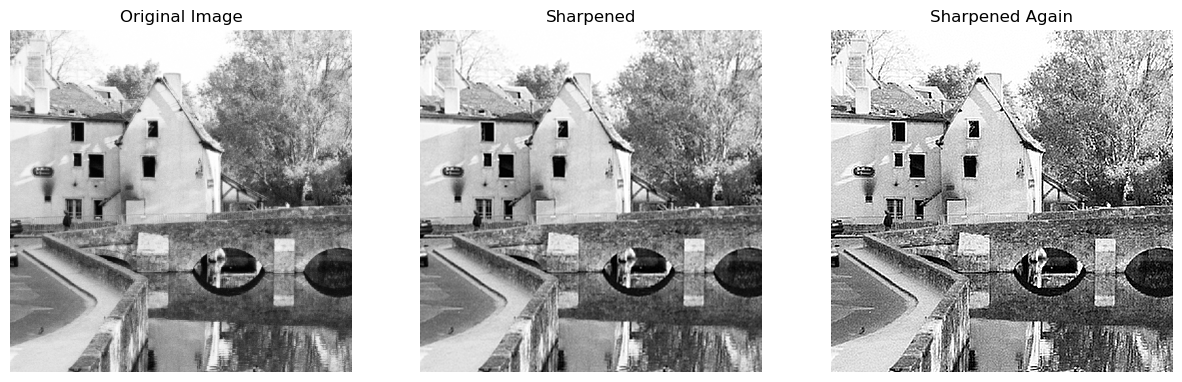

In [5]:
# Answer for C : Applying a second sharpening step to the sharpened image.
ex1_image_resharp = cv2.filter2D(ex1_image_sharp, -1, laplacian_mask)

plt.figure(figsize=(15,6))

plt.subplot(1,3,1)
plt.title('Original Image')
plt.imshow(ex1_image, cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,3,2)
plt.title('Sharpened')
plt.imshow(ex1_image_sharp, cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,3,3)
plt.title('Sharpened Again')
plt.imshow(ex1_image_resharp, cmap='gray', vmin=0, vmax=1)
plt.axis('off');
#plt.savefig('./results/q1c.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 2

Noise reduction is a crucial task to enhance the quality of images. You are provided with a noisy grayscale image, 'brain.png,' and your task is to apply noise reduction using two different methods: Median Filtering and Averaging Filtering.

**A)** Describe each of the two methods for noise reduction in images. Explain how they work and their key characteristics in addressing noise.

**B)** Apply noise reduction to the 'brain.png' image using Averaging Filtering. Use different kernel sizes (e.g., 3x3, 5x5, ...) and determine which kernel size offers a better trade-off between blurring and noise reduction for this image.

**C)** Apply noise reduction on the 'brain.png' image using Median Filtering. Use different kernel sizes (e.g., 3x3, 5x5, ...) and compare their results together in a single figure. Based on your observations, which kernel size do you think is better for noise reduction in this image?

**D)** For each of the two methods, discuss their advantages and disadvantages in the context of noise reduction. Consider aspects such as noise removal effectiveness, preservation of image details.

<img src="./imgs/brain.png" width="200" height="200"/>

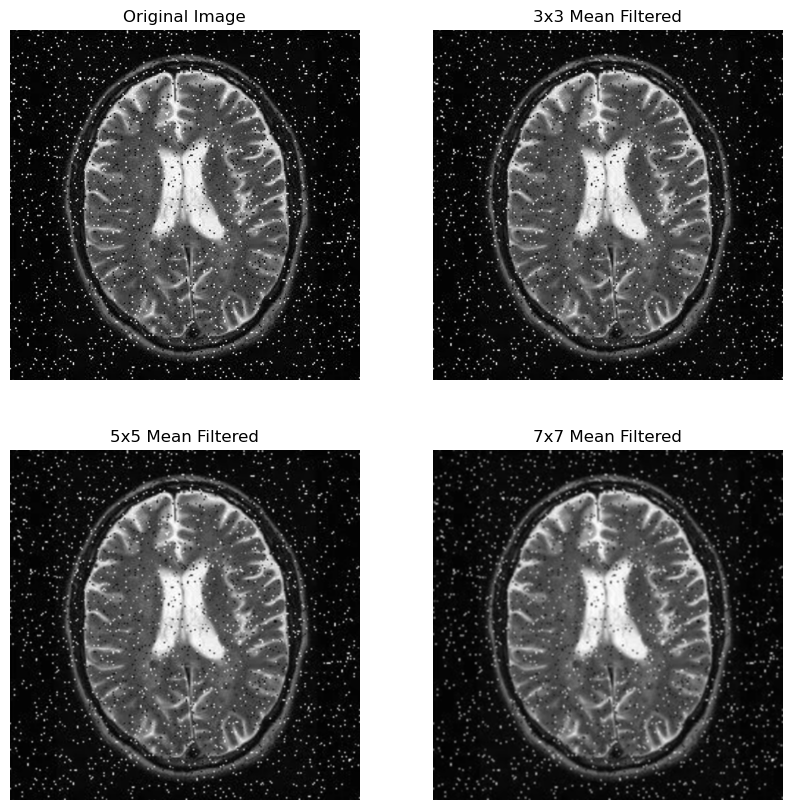

In [6]:
# Answer for B : Applying averaging filter with different kernel sizes.
ex2_image = cv2.imread('./imgs/brain.png', cv2.IMREAD_GRAYSCALE)

mask_3x3 = np.ones((3,3)) / 9
mask_5x5 = np.ones((5, 5)) / 25
mask_7x7 = np.ones((7, 7)) / 49

output_3x3 = cv2.filter2D(ex2_image, -1, mask_3x3)
output_5x5 = cv2.filter2D(ex2_image, -1, mask_5x5)
output_7x7 = cv2.filter2D(ex2_image, -1, mask_7x7)

plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(ex2_image, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title('3x3 Mean Filtered')
plt.imshow(output_3x3, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title('5x5 Mean Filtered')
plt.imshow(output_5x5, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('7x7 Mean Filtered')
plt.imshow(output_7x7, cmap='gray')
plt.axis('off');
#plt.savefig('./results/q2b.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

(-0.5, 1083.5, 1085.5, -0.5)

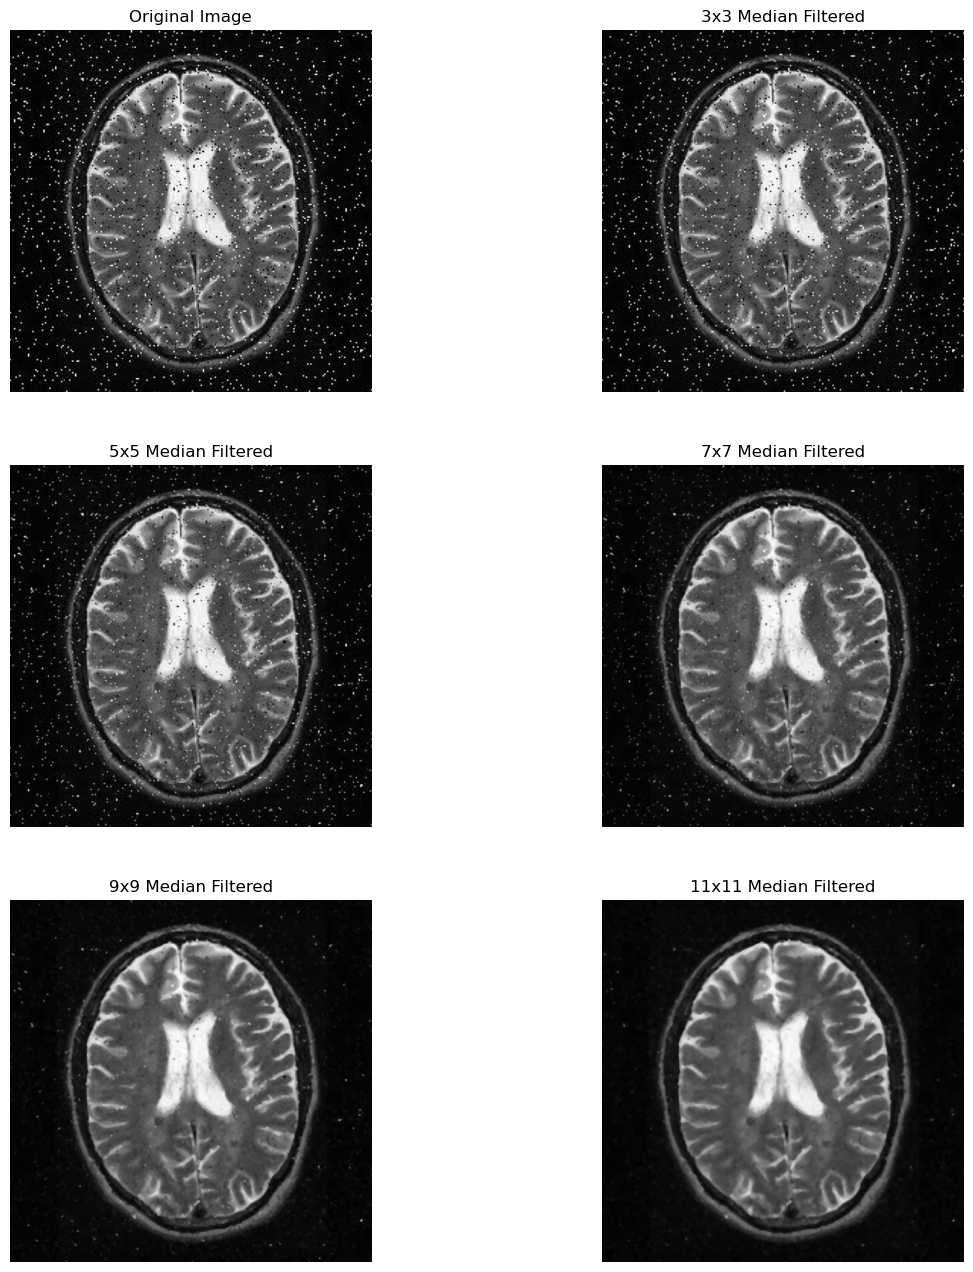

In [7]:
# Answer for C : Applying median filter with different kernel sizes.
med_3x3 = cv2.medianBlur(ex2_image, 3)
med_5x5 = cv2.medianBlur(ex2_image, 5)
med_7x7 = cv2.medianBlur(ex2_image, 7)
med_9x9 = cv2.medianBlur(ex2_image, 9)
med_11x11 = cv2.medianBlur(ex2_image, 11)

plt.figure(figsize=(14,16))

plt.subplot(3,2,1)
plt.title('Original Image')
plt.imshow(ex2_image, cmap='gray')
plt.axis('off')

plt.subplot(3,2,2)
plt.title('3x3 Median Filtered')
plt.imshow(med_3x3, cmap='gray')
plt.axis('off')

plt.subplot(3,2,3)
plt.title('5x5 Median Filtered')
plt.imshow(med_5x5, cmap='gray')
plt.axis('off')

plt.subplot(3,2,4)
plt.title('7x7 Median Filtered')
plt.imshow(med_7x7, cmap='gray')
plt.axis('off')

plt.subplot(3,2,5)
plt.title('9x9 Median Filtered')
plt.imshow(med_9x9, cmap='gray')
plt.axis('off')

plt.subplot(3,2,6)
plt.title('11x11 Median Filtered')
plt.imshow(med_11x11, cmap='gray')
plt.axis('off')

#plt.savefig('./results/q2c.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 3

The Laplacian and Sobel operators are used for edge detection, the Laplacian operator focuses on second-order derivatives to identify rapid changes in intensity, while the Sobel operator is specifically designed for computing the gradient magnitude, emphasizing edges along the horizontal and vertical directions.

**A)** When would it be more advantageous to employ Sobel edge detection versus Laplacian edge detection in image processing applications?

**B)** Open the image 'Edge.jpg,' apply the Sobel edge detector separately along the x and y dimensions, and then visualize the results for each dimension as well as the combined effect.

**C)** Open the image 'Edge.jpg,' apply the Laplacian edge detector, and display the results for Edge Detection and Magnitude.

**D)** Examine the results of these two methods and figure out which one works better for this task.

<img src="./imgs/Edge.jpg" width="200" height="200"/>

(-0.5, 599.5, 461.5, -0.5)

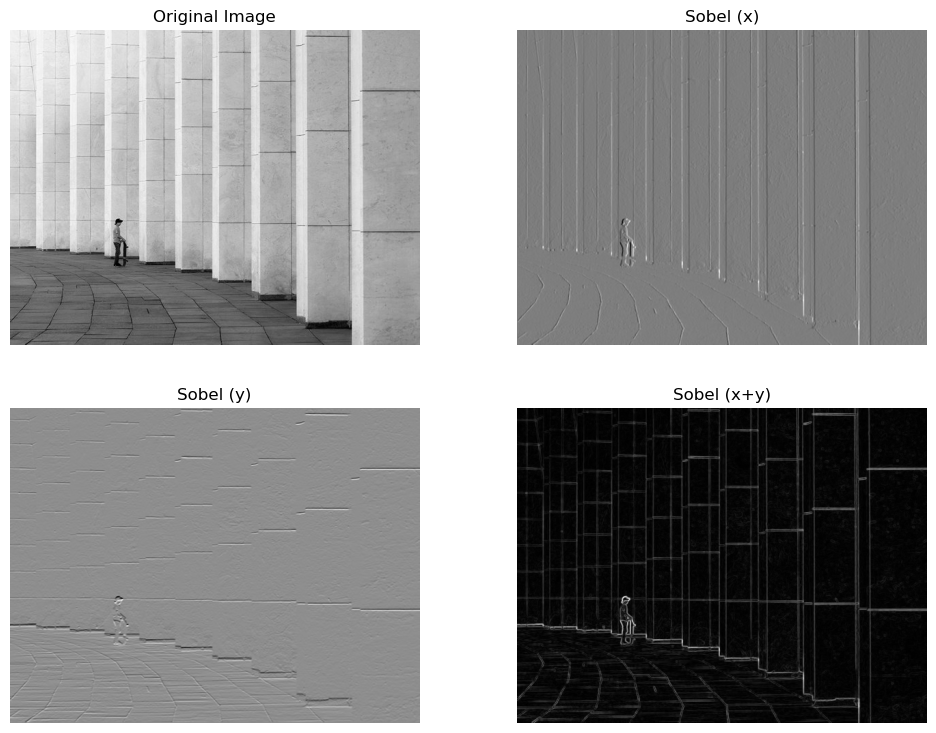

In [8]:
# Answer for B : Applying Sobel edge detection along x and y directions.
ex3_image = cv2.imread('./imgs/Edge.jpg', cv2.IMREAD_GRAYSCALE)
sobel_x = cv2.Sobel(ex3_image, cv2.CV_64F, dx=1, dy=0, ksize=3)
sobel_y = cv2.Sobel(ex3_image, cv2.CV_64F, dx=0, dy=1, ksize=3)
sobel_xy = cv2.magnitude(sobel_x, sobel_y)

plt.figure(figsize=(12,9))

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(ex3_image, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title('Sobel (x)')
plt.imshow(sobel_x, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title('Sobel (y)')
plt.imshow(sobel_y, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('Sobel (x+y)')
plt.imshow(sobel_xy, cmap='gray')
plt.axis('off')
#plt.savefig('./results/q3b.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

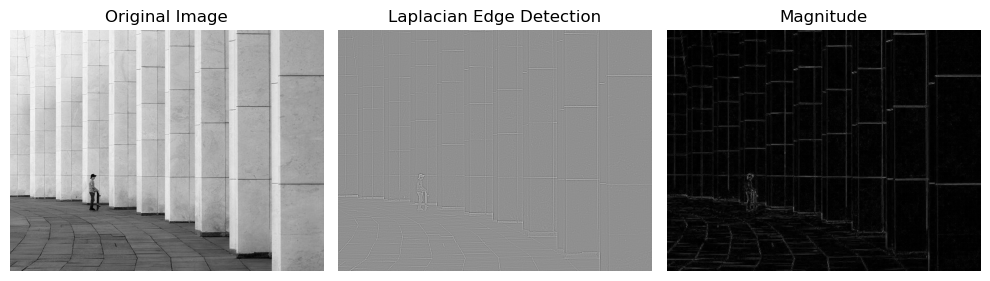

In [9]:
# Answer for C : Applying Laplacian edge detection and calculating its magnitude.
ex3_laplacian = cv2.Laplacian(ex3_image, cv2.CV_64F, ksize=3)

ex3_magnitude = np.abs(ex3_laplacian)

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(ex3_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(ex3_laplacian, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(ex3_magnitude, cmap='gray')
plt.title('Magnitude')
plt.axis('off')

plt.tight_layout()
#plt.savefig('./results/q3c.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

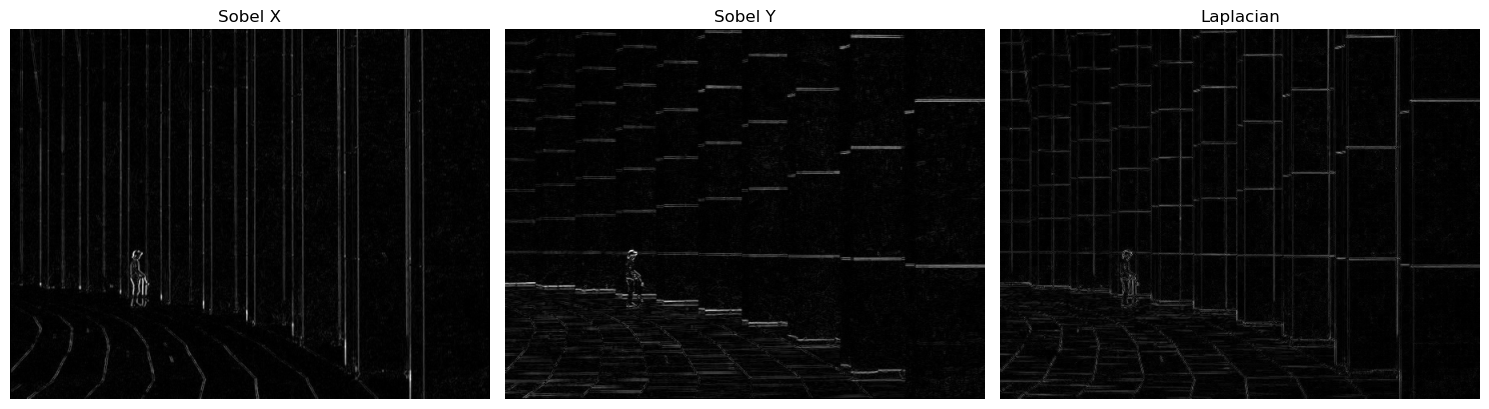

In [10]:
# Convert edge responses to absolute values for visualization
sobel_x_display = cv2.normalize(np.abs(sobel_x), None, 0, 255, cv2.NORM_MINMAX)
sobel_y_display = cv2.normalize(np.abs(sobel_y), None, 0, 255, cv2.NORM_MINMAX)
laplacian_display = cv2.normalize(np.abs(ex3_laplacian), None, 0, 255, cv2.NORM_MINMAX)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sobel_x_display, cmap='gray')
plt.title('Sobel X')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(sobel_y_display, cmap='gray')
plt.title('Sobel Y')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_display, cmap='gray')
plt.title('Laplacian')
plt.axis('off')

plt.tight_layout()
plt.show()

(-0.5, 599.5, 461.5, -0.5)

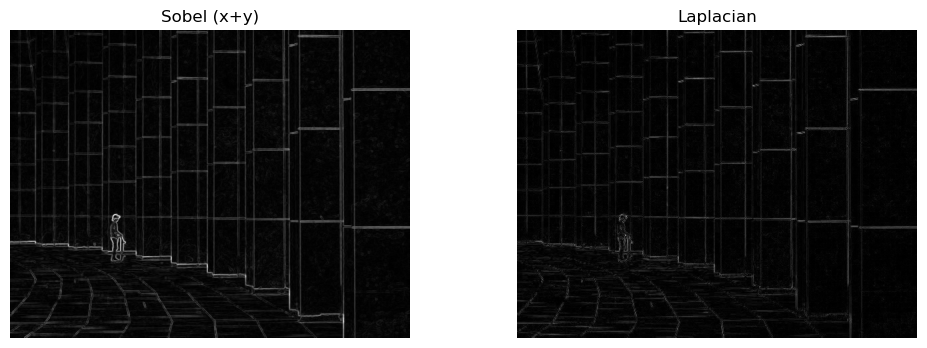

In [11]:
# Answer for D : Comparing the results of Sobel and Laplacian edge detection.
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(sobel_xy, cmap='gray')
plt.title('Sobel (x+y)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(laplacian_display, cmap='gray')
plt.title('Laplacian')
plt.axis('off')

#plt.savefig('./results/q3d.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 4

In this question, you will explore the Robert-Cross and Prewitt operators, compare their results, and then apply a high-boost filter to undo their effects. Use the image below for this question.

**A)** Briefly explain how Roberts cross-gradient operator works and then apply it on the given image and display the result.

**B)** Briefly explain how Prewitt operator works and then apply it to the given image and display the result.

**C)** Display the original image, the results of the Robert-Cross operator, and the results of the Prewitt operator side by side. 

**D)** Apply a high-boost filter to the images obtained after the Robert-Cross and Prewitt operators. Experiment with different values of 'A' and observe the changes.

**E)** Write a brief discussion on the differences observed between the results of the Roberts cross-gradient and Prewitt operators. Explain how the high-boost filter affects the results of these operators and the significance of the chosen value of ‘A’.

<img src="./imgs/cat.gif" width="200" height="200"/>

(-0.5, 511.5, 511.5, -0.5)

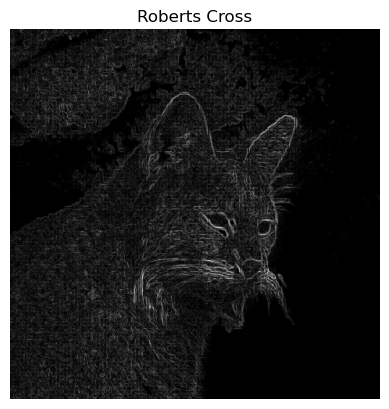

In [12]:
# Answer for A : Applying Roberts Cross edge detection.
cap = cv2.VideoCapture("./imgs/cat.gif")
_, ex4_image = cap.read()
cap.release()
ex4_image = cv2.cvtColor(ex4_image, cv2.COLOR_BGR2GRAY)

roberts_cross_h1 = np.array([[1, 0], [0, -1]])
roberts_cross_h2 = np.array([[0, 1], [-1, 0]])

ex4_h1 = cv2.filter2D(ex4_image, ddepth=cv2.CV_64F, kernel=roberts_cross_h1)
ex4_h2 = cv2.filter2D(ex4_image, ddepth=cv2.CV_64F, kernel=roberts_cross_h2)

robert_edged_image = np.sqrt(ex4_h1**2 + ex4_h2**2)
plt.imshow(robert_edged_image, cmap='gray')
plt.title('Roberts Cross')
plt.axis('off')
#plt.savefig('./results/q4a.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

(-0.5, 511.5, 511.5, -0.5)

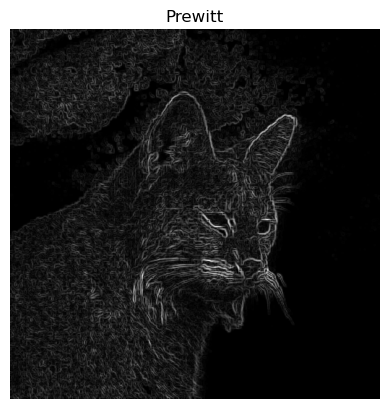

In [13]:
# Answer for B : Applying Prewitt edge detection.
prewitt_x = np.array([[-1,-1,-1],[0,0,0],[1,1,1]])
prewitt_y = np.array([[-1,0,1],[-1,0,1],[-1,0,1]])

prewitt_x_image = cv2.filter2D(ex4_image, ddepth=cv2.CV_64F, kernel=prewitt_x)
prewitt_y_image = cv2.filter2D(ex4_image, ddepth=cv2.CV_64F, kernel=prewitt_y)
prewitt_edged_image = np.sqrt(prewitt_x_image**2 + prewitt_y_image**2)
plt.imshow(prewitt_edged_image, cmap='gray')
plt.title('Prewitt')
plt.axis('off')
#plt.savefig('./results/q4b.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

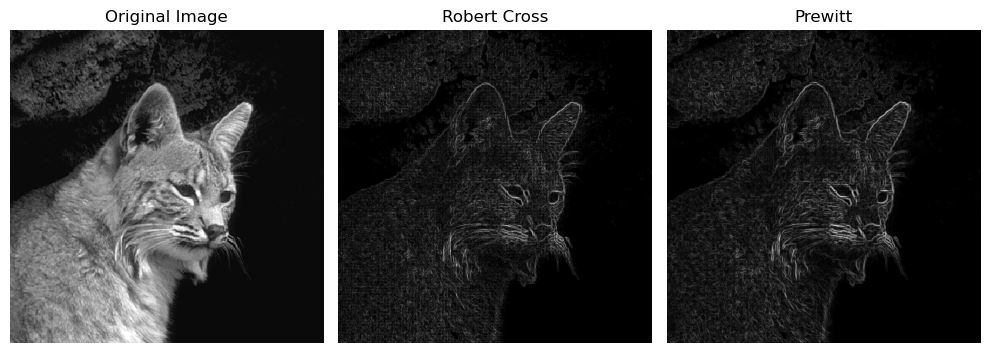

In [14]:
# Answer for C : Comparing the original image with Roberts Cross and Prewitt results.
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(ex4_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(robert_edged_image, cmap='gray')
plt.title('Robert Cross')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(prewitt_edged_image, cmap='gray')
plt.title('Prewitt')
plt.axis('off')

plt.tight_layout()
#plt.savefig('./results/q4c.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

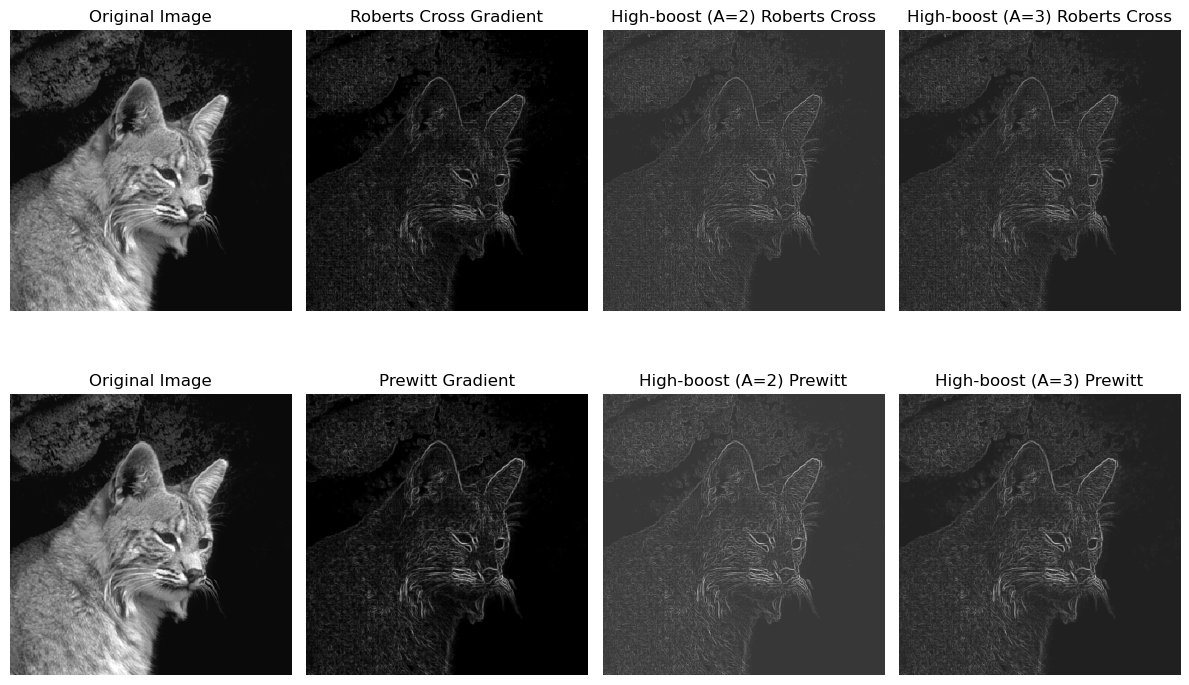

In [15]:
# Answer for D : Applying high-boost filtering with different values of A.

roberts_blurred = cv2.GaussianBlur(robert_edged_image, (5, 5), 0)
prewitt_blurred = cv2.GaussianBlur(prewitt_edged_image, (5, 5), 0)

A = 2

hbf1 = A * robert_edged_image - roberts_blurred
hbf2 = A * prewitt_edged_image - prewitt_blurred

A = 3

hbf3 = A * robert_edged_image - roberts_blurred
hbf4 = A * prewitt_edged_image - prewitt_blurred

plt.figure(figsize=(12, 8))

plt.subplot(2, 4, 1)
plt.imshow(ex4_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 4, 2)
plt.imshow(robert_edged_image, cmap='gray')
plt.title('Roberts Cross Gradient')
plt.axis('off')

plt.subplot(2, 4, 3)
plt.imshow(hbf1, cmap='gray')
plt.title('High-boost (A=2) Roberts Cross')
plt.axis('off')

plt.subplot(2, 4, 4)
plt.imshow(hbf3, cmap='gray')
plt.title('High-boost (A=3) Roberts Cross')
plt.axis('off')

plt.subplot(2, 4, 5)
plt.imshow(ex4_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 4, 6)
plt.imshow(prewitt_edged_image, cmap='gray')
plt.title('Prewitt Gradient')
plt.axis('off')

plt.subplot(2, 4, 7)
plt.imshow(hbf2, cmap='gray')
plt.title('High-boost (A=2) Prewitt')
plt.axis('off')

plt.subplot(2, 4, 8)
plt.imshow(hbf4, cmap='gray')
plt.title('High-boost (A=3) Prewitt')
plt.axis('off')


plt.tight_layout()
#plt.savefig('./results/q4d.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 5

To achieve successful image enhancement, it is often ineffective to rely on a single operation. Instead, a combination of techniques is utilized to attain the desired final result. Please open the image 'skeleton.png' and apply the enhancement methods you have already learned, incorporating spatial enhancement techniques.

**A)** Open the image 'skeleton.png,' apply your desired enhancement methods to achieve the best visibility of the bones. Explain your methods and why you chose them.

**B)** Compare the original image with your enhanced version in a single figure, illustrating them before and after enhancement.

<img src="./imgs/skeleton.png" width="200" height="200"/>

(-0.5, 451.5, 719.5, -0.5)

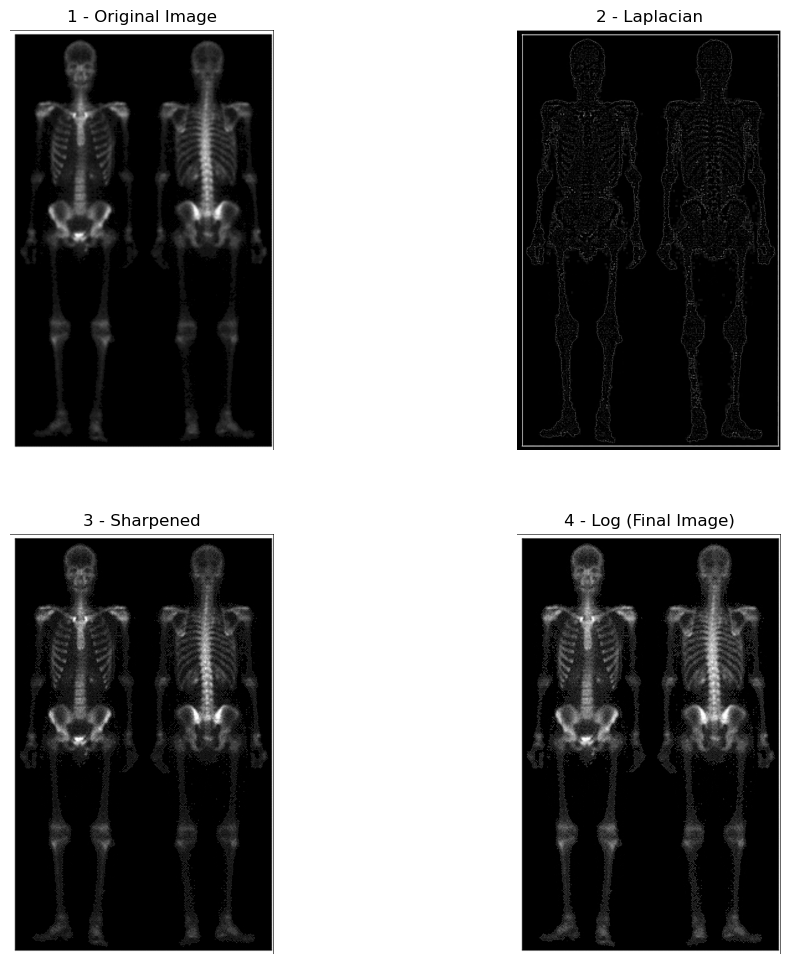

In [16]:
# Answer for A and B : Applying image enhancement techniques and comparing the original and enhanced images.
ex5_image = cv2.imread('./imgs/skeleton.png', cv2.IMREAD_GRAYSCALE)

laplacian_mask = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

ex5_image_lf = cv2.Laplacian(ex5_image, -1, ksize=3)

ex5_image_sharp = cv2.filter2D(ex5_image, -1, laplacian_mask)

def secondfunc(img, c=1):
    img = c * np.log10(img + 1)
    return img

ex5_image_sharp_normal = minmax_normalize(ex5_image_sharp)
ex5_log_applied = minmax_normalize(secondfunc(ex5_image_sharp_normal, c=4))

plt.figure(figsize=(12,12))

plt.subplot(2,2,1)
plt.imshow(ex5_image, cmap='gray')
plt.title('1 - Original Image')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(ex5_image_lf, cmap='gray')
plt.title('2 - Laplacian')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(ex5_image_sharp, cmap='gray')
plt.title('3 - Sharpened')
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(ex5_log_applied, cmap='gray', vmin=0, vmax=1)
plt.title('4 - Log (Final Image)')
plt.axis('off')
#plt.savefig('./results/q5.jpg', format='jpg', bbox_inches="tight", pad_inches=0)